# Predicted and observed Hi-C in four GM12878 chr7 regions

Predict Hi-C from DNA and four omics tracks for four fixed regions, then display the predicted and observed maps with CTCF/DNase tracks.

Use the GM12878 checkpoint. Observed targets use `log2(Hi-C + 1)`, retain the diagonal, and receive no smoothing or additional normalization. Each predicted/observed pair shares the observed map's 99th-percentile color limit.

## Environment, paths, and parameters


In [ ]:
from pathlib import Path
import sys
from io import BytesIO
import os

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((parent for parent in [cwd, *cwd.parents]
                     if (parent / "data").is_dir() and (parent / "notebooks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find the repository's data and notebooks directories.")
sys.dont_write_bytecode = True
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import torch
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from data import HiCDataAndOmicsDataset, load_sample
from models import build_model

MODEL_TYPE = 'gm12878_legacy'
ACCESSIBILITY_LABEL = 'DNase'
DATA_DIR = PROJECT_ROOT / "data" / "hic_maps"
WEIGHTS = Path("../../weights/gm12878/best_model.pth")
DEVICE = torch.device('cpu')
DPI = 300
torch.set_num_threads(4)
torch.manual_seed(42)
np.random.seed(42)
WINDOW_FILES = (
    'chr7_6976000_8000000.pkl',
    'chr7_20864000_21888000.pkl',
    'chr7_40256000_41280000.pkl',
    'chr7_97728000_98752000.pkl',
)
INTERVAL_LABELS = ('6.98–8.00 Mb', '20.86–21.88 Mb', '40.26–41.28 Mb', '97.73–98.75 Mb')


## Load the model and checkpoint


In [3]:
sample_paths = [DATA_DIR / name for name in WINDOW_FILES]
first_raw = load_sample(sample_paths[0])
data_omics = int(first_raw["omics_signals"].shape[0])
target_len = int(first_raw["omics_signals"].shape[-1])

state = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
if isinstance(state, dict) and "model_state_dict" in state:
    state = state["model_state_dict"]
elif isinstance(state, dict) and "state_dict" in state:
    state = state["state_dict"]

state = {
    key.removeprefix("module."): value
    for key, value in state.items()
}

weight_omics = int(state["omics_encoder.downsampler.0.weight"].shape[1])
assert data_omics == 4 and target_len == 512
assert weight_omics == data_omics

model = build_model(
    MODEL_TYPE,
    num_omics_features=data_omics,
    target_len=target_len,
).to(DEVICE)

model.load_state_dict(state, strict=True)
model.eval()


## Predict the four windows


In [4]:
records = []
for index, sample_path in enumerate(sample_paths):
    raw = load_sample(sample_path)
    dataset = HiCDataAndOmicsDataset([sample_path], log_hic=True, zero_diagonal=False)
    sequence, omics, truth = dataset[0]
    with torch.inference_mode():
        with torch.amp.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
            prediction = model(sequence.unsqueeze(0).to(DEVICE), omics.unsqueeze(0).to(DEVICE))
    prediction_array = prediction.squeeze(0).float().cpu().numpy()
    truth_array = truth.numpy()
    omics_array = omics.numpy()
    assert prediction_array.shape == (512, 512) and np.isfinite(prediction_array).all()
    assert np.array_equal(truth_array, np.log2(raw['hic_matrix'].astype(np.float32) + 1.0))
    positive_truth = truth_array[truth_array > 0]
    vmax = float(np.percentile(positive_truth, 99)) if positive_truth.size else 1.0
    records.append({
        'prediction': prediction_array, 'truth': truth_array, 'omics': omics_array,
        'vmax': vmax, 'display_interval': INTERVAL_LABELS[index],
    })


## Combined four-region figure


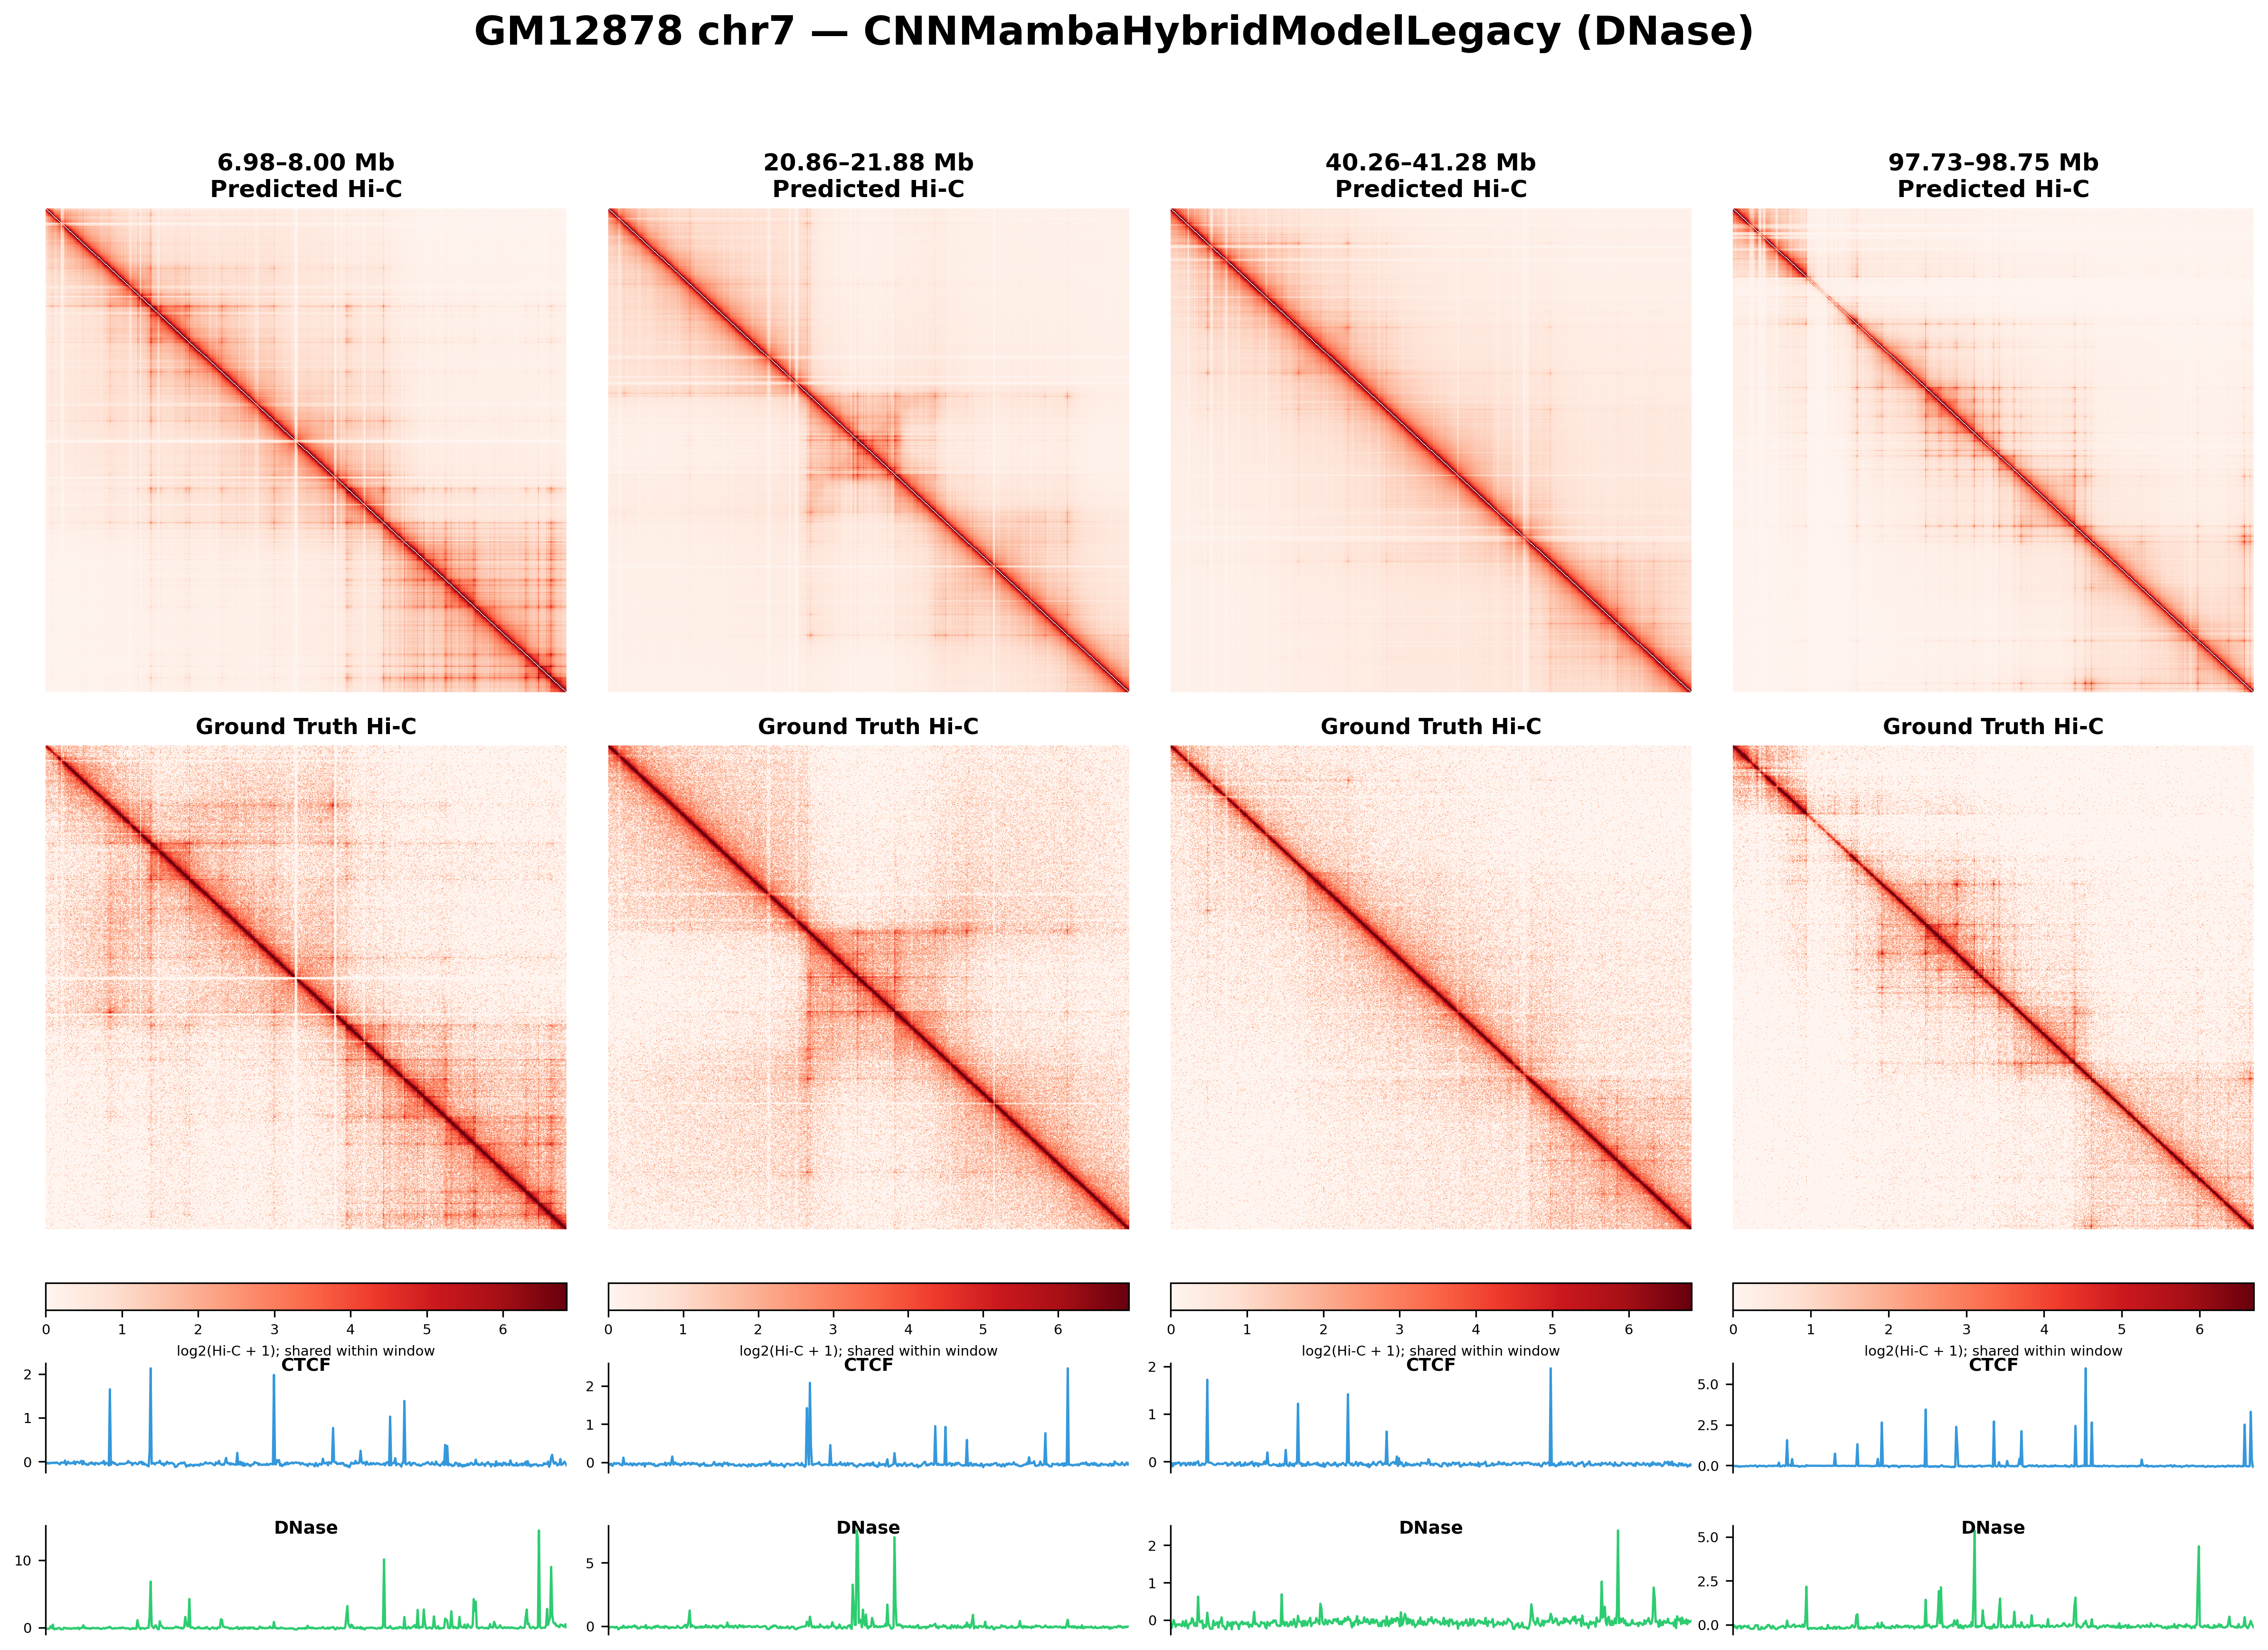

In [9]:
def plot_combined(
    records: list[dict],
    dpi: int,
    model_label: str,
    accessibility_label: str,
):
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.gridspec as gridspec
    import matplotlib.pyplot as plt

    figure = plt.figure(figsize=(20, 13))
    grid = gridspec.GridSpec(
        5,
        4,
        height_ratios=[8.0, 8.0, 0.45, 1.8, 1.8],
        hspace=0.22,
        wspace=0.08,
    )
    figure.suptitle(
        f"GM12878 chr7 — {model_label}",
        fontsize=20,
        y=0.985,
        fontweight="bold",
    )

    for column, record in enumerate(records):
        prediction = record["prediction"]
        truth = record["truth"]
        omics = record["omics"]
        vmax = record["vmax"]
        interval_label = record["display_interval"]

        prediction_axis = figure.add_subplot(grid[0, column])
        prediction_axis.imshow(
            prediction,
            cmap="Reds",
            vmin=0.0,
            vmax=vmax,
            aspect="auto",
            interpolation="nearest",
        )
        prediction_axis.set_title(
            f"{interval_label}\nPredicted Hi-C",
            fontsize=12,
            fontweight="bold",
        )
        prediction_axis.axis("off")

        truth_axis = figure.add_subplot(grid[1, column])
        truth_image = truth_axis.imshow(
            truth,
            cmap="Reds",
            vmin=0.0,
            vmax=vmax,
            aspect="auto",
            interpolation="nearest",
        )
        truth_axis.set_title("Ground Truth Hi-C", fontsize=11, fontweight="bold")
        truth_axis.axis("off")

        color_axis = figure.add_subplot(grid[2, column])
        colorbar = figure.colorbar(truth_image, cax=color_axis, orientation="horizontal")
        colorbar.ax.tick_params(labelsize=7)
        colorbar.set_label("log2(Hi-C + 1); shared within window", fontsize=7)

        for row, channel, label, color in (
            (3, 0, "CTCF", "#3498db"),
            (4, 1, accessibility_label, "#2ecc71"),
        ):
            track_axis = figure.add_subplot(grid[row, column])
            track_axis.plot(omics[channel], color=color, linewidth=1.15)
            track_axis.set_title(label, fontsize=9, y=0.82, fontweight="bold")
            track_axis.spines[["top", "right", "bottom"]].set_visible(False)
            track_axis.tick_params(axis="y", labelsize=7)
            track_axis.set_xticks([])
            track_axis.set_xlim(0, omics.shape[-1] - 1)


    return figure

assert len(records) == 4
figure = plot_combined(records, DPI,
                       model_label=f'{type(model).__name__} ({ACCESSIBILITY_LABEL})',
                       accessibility_label=ACCESSIBILITY_LABEL)
with BytesIO() as buffer:
    figure.savefig(buffer, format='png', dpi=DPI, bbox_inches='tight')
    display(Image(data=buffer.getvalue(), width=1500))
plt.close(figure)
